# Ghost Band Research

This notebook replays the V2 VWAP engine on historical US100 M1 data to study how the Gaussian ghost bands behave alongside the solid bands.

## 1. Data and replay

Use 90 minutes of pre-anchor context for the solid band width. Anchor VWAP
at 09:00 New York time, warm up for 30 minutes, and study the candles from
09:30 up to the 12:30 cutoff.

In [21]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

report_charts = project_root / "artifacts" / "report_charts"
report_charts.mkdir(parents=True, exist_ok=True)

def save_report_figure(fig, filename):
    fig.savefig(
        report_charts / filename,
        dpi=180,
        bbox_inches="tight",
        facecolor=fig.get_facecolor(),
    )
    print(f"Saved {(report_charts / filename).resolve()}")

from src.config import CONFIG
from src.engine import EngineState, update_engine_state
from src.loaders import load_mt5_csv
from src.replay import run_replay

NY_TZ = "America/New_York"
CSV_PATH = CONFIG["data_dir"] / "2025_full_year.csv"

SOLID_PRE_ANCHOR_MINUTES = 90
WARMUP_MINUTES = 30
TRADE_OPEN = "09:30"
TRADE_CUTOFF = "12:30"

bars = (
    load_mt5_csv(str(CSV_PATH))
    .drop_duplicates(subset="datetime")
    .set_index("datetime")
    .sort_index()
    .tz_convert(NY_TZ)
)

✅ MT5 CSV loaded: 348,793 bars from C:\GitHub Projects\VWAP-probability-band-engine-v3\data\historical\2025_full_year.csv


### Minute-by-minute replay

Start a fresh engine each day. Check the 09:30 VWAP against the
tick-volume-weighted average of the 30 warmup candles. Pair each candle
in the research window with the band snapshot from the previous close.

In [13]:
probability_table = pd.DataFrame(columns=["zone"])
sessions = []
skipped_days = []

for day, day_bars in bars.groupby(bars.index.date):
    trade_open = pd.Timestamp(f"{day} {TRADE_OPEN}", tz=NY_TZ)
    cutoff = pd.Timestamp(f"{day} {TRADE_CUTOFF}", tz=NY_TZ)
    anchor = trade_open - pd.Timedelta(minutes=WARMUP_MINUTES)
    context_start = anchor - pd.Timedelta(minutes=SOLID_PRE_ANCHOR_MINUTES)

    required = pd.date_range(context_start, cutoff, freq="min", inclusive="left")
    missing = required.difference(day_bars.index)
    if len(missing):
        skipped_days.append({"session_date": day, "missing_bars": len(missing)})
        continue

    replay_bars = day_bars.loc[required].rename_axis("datetime")
    config = {**CONFIG, "vwap_anchor_utc": anchor}
    rows = []

    for state in run_replay(
        replay_bars.reset_index(),
        config,
        probability_table,
        EngineState=EngineState,
        update_engine_state=update_engine_state,
        speed=100_000,
    ):
        rows.append({
            "datetime": state.datetime,
            "vwap": state.reference,
            **{f"solid_{key}": value for key, value in state.bands.items()},
            **{f"ghost_{key}": value for key, value in state.ghost_bands.items()},
        })

    snapshots = pd.DataFrame(rows).set_index("datetime")
    seed = replay_bars.loc[(required >= anchor) & (required < trade_open)]
    expected_vwap = np.average(seed["typical_price"], weights=seed["tick_volume"])

    candles = replay_bars.loc[required >= trade_open, ["open", "high", "low", "close"]]
    session = candles.join(snapshots.shift(1))

    assert np.isclose(session["vwap"].iloc[0], expected_vwap, rtol=0, atol=1e-8)
    sessions.append(session.assign(session_date=day))

if not sessions:
    raise ValueError("No dates have the full pre-anchor, warmup and trading window.")

trade_bars = pd.concat(sessions)
print(f"Replayed {len(sessions)} dates and {len(trade_bars):,} trading-window candles.")
print(f"Skipped {len(skipped_days)} dates with incomplete coverage.")

Replayed 254 dates and 45,720 trading-window candles.
Skipped 58 dates with incomplete coverage.


### Replay chart

Pair each candle with the VWAP and band levels calculated at the previous close. This is the timing we'll use to test whether a wick reached a band that was already visible.

Saved C:\GitHub Projects\VWAP-probability-band-engine-v3\artifacts\report_charts\ghost_band_replay.png


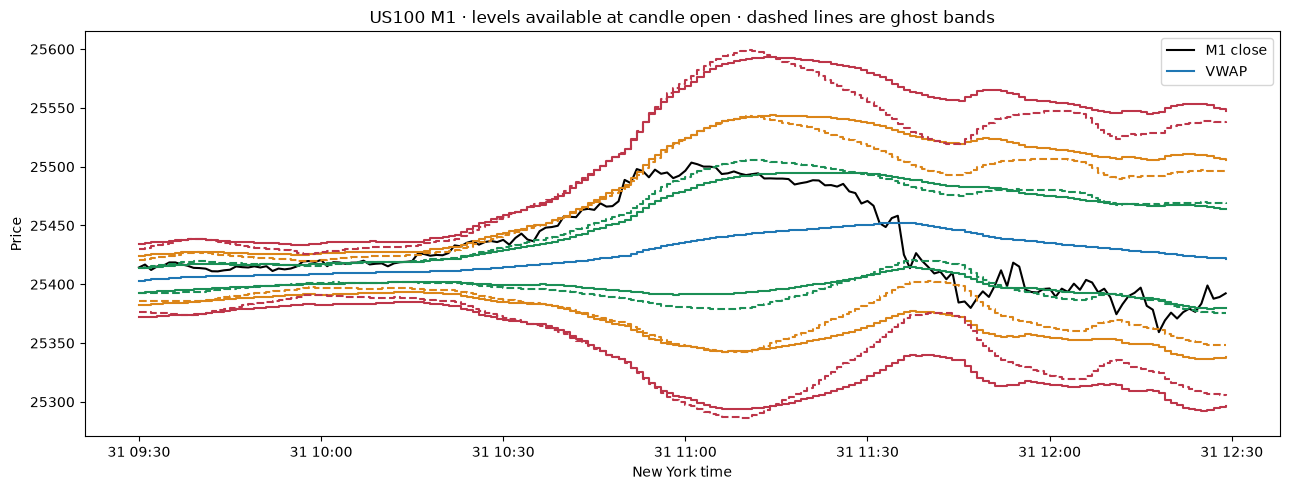

In [23]:
plot_day = trade_bars["session_date"].iloc[-1]
chart = trade_bars.loc[trade_bars["session_date"] == plot_day]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(chart.index, chart["close"], color="black", label="M1 close")
ax.step(chart.index, chart["vwap"], where="post", color="tab:blue", label="VWAP")

colors = ["#1b8f56", "#db8519", "#bd3549"]
for level, color in enumerate(colors, start=1):
    for sign in ("+", "-"):
        ax.step(chart.index, chart[f"solid_{level}{sign}"], where="post", color=color)
        ax.step(
            chart.index,
            chart[f"ghost_{level}{sign}"],
            where="post",
            color=color,
            linestyle="--",
        )

ax.set_title("US100 M1 · levels available at candle open · dashed lines are ghost bands")
ax.set_xlabel("New York time")
ax.set_ylabel("Price")
ax.legend()
fig.tight_layout()
save_report_figure(fig, "ghost_band_replay.png")
plt.show()

Saved C:\GitHub Projects\VWAP-probability-band-engine-v3\artifacts\report_charts\ghost_band_probability_heatmap.png


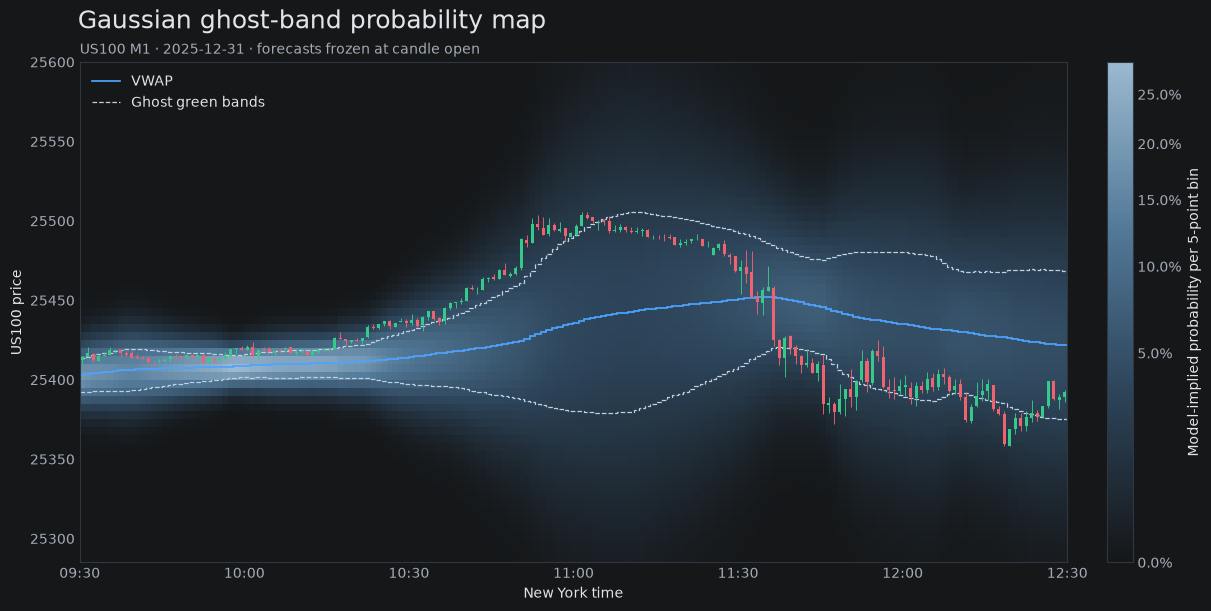

In [22]:
from statistics import NormalDist

import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, PowerNorm
from matplotlib.ticker import PercentFormatter
from scipy.special import ndtr

heatmap_bars = chart
vwap = heatmap_bars["vwap"].to_numpy()
green_z = NormalDist().inv_cdf(CONFIG["ghost_upper_percentiles"][0])
sigma = (heatmap_bars["ghost_1+"] - heatmap_bars["ghost_1-"]) / (2 * green_z)
sigma = sigma.where(sigma > 0).to_numpy()

bin_size = 5
price_low = heatmap_bars[["low", "ghost_3-"]].min().min()
price_high = heatmap_bars[["high", "ghost_3+"]].max().max()
bottom = bin_size * np.floor(price_low / bin_size)
top = bin_size * np.ceil(price_high / bin_size)
price_edges = np.arange(bottom, top + bin_size, bin_size)

# The probability in each price bin is the difference between its two CDF values.
z_edges = (price_edges[:, None] - vwap) / sigma
bin_probability = np.diff(ndtr(z_edges), axis=0)

minute = 1 / (24 * 60)
starts = mdates.date2num(heatmap_bars.index)
time_edges = np.r_[starts, starts[-1] + minute]
centres = starts + minute / 2

bg, fg, muted = "#151719", "#E1E4E8", "#A3ABB5"
cmap = LinearSegmentedColormap.from_list(
    "ghost_probability", [bg, "#2C4358", "#527998", "#9BB9D0"]
)
fig, ax = plt.subplots(figsize=(12, 6), facecolor=bg, layout="constrained")
ax.set_facecolor(bg)

heatmap = ax.pcolormesh(
    time_edges, price_edges, bin_probability,
    cmap=cmap, shading="flat",
    norm=PowerNorm(gamma=0.5, vmin=0),
)
ax.stairs(
    vwap, time_edges, baseline=None,
    color="#4DA3FF", linewidth=1.25, label="VWAP",
)
for side in ("+", "-"):
    ax.stairs(
        heatmap_bars[f"ghost_1{side}"], time_edges, baseline=None,
        color="#BDD1E2", linewidth=0.9, linestyle="--",
        label="Ghost green bands" if side == "+" else None,
    )

opens = heatmap_bars["open"].to_numpy()
closes = heatmap_bars["close"].to_numpy()
candle_colors = np.where(closes >= opens, "#35C98A", "#EF6270")
ax.vlines(
    centres, heatmap_bars["low"], heatmap_bars["high"],
    colors=candle_colors, linewidth=0.65,
)
ax.bar(
    centres, closes - opens, bottom=opens, width=0.55 * minute,
    color=candle_colors, linewidth=0, zorder=3,
)

tz = heatmap_bars.index.tz
ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 30], tz=tz))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=tz))
ax.set_xlim(time_edges[0], time_edges[-1])
ax.set_ylim(price_edges[0], price_edges[-1])
ax.set_xlabel("New York time", color=fg)
ax.set_ylabel("US100 price", color=fg)
ax.tick_params(colors=muted, length=0)
for spine in ax.spines.values():
    spine.set_color("#303740")
ax.legend(loc="upper left", frameon=False, labelcolor=fg)

cbar = fig.colorbar(heatmap, ax=ax, pad=0.02)
cbar.ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
cbar.ax.tick_params(colors=muted, length=0)
cbar.outline.set_edgecolor("#303740")
cbar.set_label(f"Model-implied probability per {bin_size}-point bin", color=fg)

fig.suptitle(
    "Gaussian ghost-band probability map",
    x=0.06, ha="left", color=fg, fontsize=18,
)
ax.set_title(
    f"US100 M1 · {plot_day} · forecasts frozen at candle open",
    loc="left", color=muted, fontsize=10,
)
save_report_figure(fig, "ghost_band_probability_heatmap.png")
plt.show()

## 2. Gaussian calibration

Compare each candle's close with the ghost bands available at its open.
Use every replay bar with a close and all six band levels.

Report exceedance rates for each tail, with pointwise 95% intervals
from resampling whole sessions. Mean width is the distance between
the matching upper and lower levels, averaged across eligible bars.

,nominal,tail,exceedances,eligible_bars,observed,ci_low,ci_high,mean_width_pts
0,0.50%,Lower,578,45720,1.26%,1.10%,1.45%,147.38
1,0.50%,Upper,396,45720,0.87%,0.75%,1.00%,147.38
2,5.00%,Lower,3288,45720,7.19%,6.59%,7.83%,94.11
3,5.00%,Upper,3191,45720,6.98%,6.42%,7.53%,94.11
4,15.00%,Lower,9322,45720,20.39%,18.69%,22.13%,59.30
5,15.00%,Upper,11164,45720,24.42%,22.56%,26.19%,59.30


Saved C:\GitHub Projects\VWAP-probability-band-engine-v3\artifacts\report_charts\ghost_band_gaussian_calibration.png


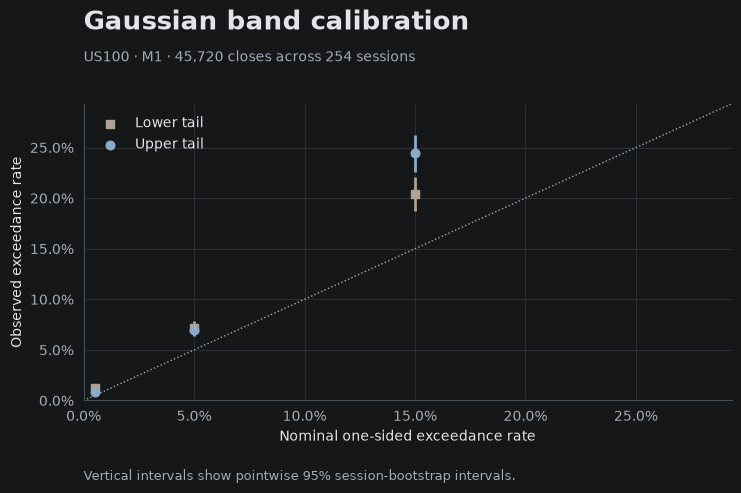

In [24]:
from matplotlib.ticker import PercentFormatter

pairs = [
    (f"ghost_{level}-", f"ghost_{level}+", 1 - percentile)
    for level, percentile in enumerate(CONFIG["ghost_upper_percentiles"], start=1)
]
band_columns = [band for lower, upper, _ in pairs for band in (lower, upper)]
eligible = trade_bars.dropna(subset=["close", *band_columns])
if eligible.empty:
    raise ValueError("No replay bars have a close and all six ghost levels.")

tail_hits = {}
average_widths = {}

for lower, upper, nominal in pairs:
    width = (eligible[upper] - eligible[lower]).mean()
    for tail, hit in {
        "Lower": eligible["close"] < eligible[lower],
        "Upper": eligible["close"] > eligible[upper],
    }.items():
        key = (nominal, tail)
        tail_hits[key] = hit
        average_widths[key] = width

hits = pd.DataFrame(tail_hits)
by_session = hits.groupby(eligible["session_date"], sort=True)
session_hits = by_session.sum()
session_bars = by_session.size().to_numpy()
n_sessions = len(session_bars)

draws = np.random.default_rng(2025).multinomial(
    n_sessions, np.full(n_sessions, 1 / n_sessions), size=2_000
)
boot_rates = (draws @ session_hits.to_numpy()) / (draws @ session_bars)[:, None]
ci_low, ci_high = np.percentile(boot_rates, [2.5, 97.5], axis=0)

calibration = pd.DataFrame({
    "nominal": [key[0] for key in hits.columns],
    "tail": [key[1] for key in hits.columns],
    "exceedances": hits.sum().to_numpy(),
    "eligible_bars": len(eligible),
    "observed": hits.mean().to_numpy(),
    "ci_low": ci_low,
    "ci_high": ci_high,
    "mean_width_pts": [average_widths[key] for key in hits.columns],
}).sort_values(["nominal", "tail"]).reset_index(drop=True)

percent_cols = ["nominal", "observed", "ci_low", "ci_high"]
table = calibration.copy()
table[percent_cols] = table[percent_cols].apply(
    lambda col: col.map(lambda rate: f"{rate:.2%}")
)
display(table.round({"mean_width_pts": 2}))

background, foreground, muted = "#151719", "#E1E4E8", "#A3ABB5"
fig, ax = plt.subplots(figsize=(8, 5.3), facecolor=background)
ax.set_facecolor(background)
fig.subplots_adjust(left=0.14, right=0.95, top=0.78, bottom=0.22)

limit = 1.12 * max(calibration["nominal"].max(), calibration["ci_high"].max())
ax.plot([0, limit], [0, limit], color=muted, linestyle=":", linewidth=1)

for tail, color, marker in (("Lower", "#B0A293", "s"), ("Upper", "#8CABCA", "o")):
    rows = calibration.loc[calibration["tail"] == tail]
    ax.vlines(rows["nominal"], rows["ci_low"], rows["ci_high"], color=color, linewidth=2)
    ax.scatter(
        rows["nominal"], rows["observed"], color=color, marker=marker,
        s=38, label=f"{tail} tail", zorder=3,
    )

ax.set(xlim=(0, limit), ylim=(0, limit))
ax.set_xlabel("Nominal one-sided exceedance rate", color=foreground)
ax.set_ylabel("Observed exceedance rate", color=foreground)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_axisbelow(True)
ax.grid(color="#2F343B", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
for spine in ("bottom", "left"):
    ax.spines[spine].set_color("#45505A")
ax.tick_params(colors=muted, length=0, pad=7)
ax.legend(loc="upper left", frameon=False, labelcolor=foreground)

fig.text(
    0.14, 0.92, "Gaussian band calibration",
    color=foreground, fontsize=19, weight="semibold",
)
fig.text(
    0.14, 0.86, f"US100 · M1 · {len(eligible):,} closes across {n_sessions} sessions",
    color=muted, fontsize=10,
)
fig.text(
    0.14, 0.07, "Vertical intervals show pointwise 95% session-bootstrap intervals.",
    color=muted, fontsize=9,
)
save_report_figure(fig, "ghost_band_gaussian_calibration.png")
plt.show()

## 3. Wick event study

A long wick setup opens above upper green, touches it, and closes back
above it. A short setup mirrors this at lower green. Each candle is
tested against the solid and ghost levels available at its open.

Classify each setup as solid only, ghost only, or both. A label describes
which band satisfied the full wick rule.

In [17]:
def green_wick_flags(bars, band_set):
    upper = bars[f"{band_set}_1+"]
    lower = bars[f"{band_set}_1-"]

    long_wick = (
        bars["open"].gt(upper)
        & bars["low"].le(upper)
        & bars["close"].gt(upper)
    )
    short_wick = (
        bars["open"].lt(lower)
        & bars["high"].ge(lower)
        & bars["close"].lt(lower)
    )

    return {"long": long_wick, "short": short_wick}


def classify_wick_events(comparable_bars):
    solid_flags = green_wick_flags(comparable_bars, "solid")
    ghost_flags = green_wick_flags(comparable_bars, "ghost")
    event_frames = []

    for side in ("long", "short"):
        solid_hit = solid_flags[side]
        ghost_hit = ghost_flags[side]
        is_event = solid_hit | ghost_hit

        events = comparable_bars.loc[is_event].copy()
        events["side"] = side
        events["setup"] = np.select(
            [(solid_hit & ghost_hit).loc[is_event], solid_hit.loc[is_event]],
            ["both", "solid_only"],
            default="ghost_only",
        )
        event_frames.append(events)

    return pd.concat(event_frames).sort_index()


green_columns = ["solid_1+", "solid_1-", "ghost_1+", "ghost_1-"]
comparable_bars = trade_bars.dropna(subset=green_columns)
wick_events = classify_wick_events(comparable_bars)
setup_counts = pd.crosstab(wick_events["side"], wick_events["setup"]).reindex(
    index=["long", "short"],
    columns=["solid_only", "ghost_only", "both"],
    fill_value=0,
)

display(setup_counts)

setup,solid_only,ghost_only,both
side,,,
long,1086,1092,462
short,853,932,394


### Measure forward moves

Measure the signed price move from the next candle's open to each of
the next 30 closes. A positive move means price went in the setup direction.

Score events with a full 30-minute window within the same session.
Report both the total setups and how many were scored.

In [18]:
HORIZONS = range(1, 31)
setup_order = ["solid_only", "ghost_only", "both"]
session_groups = trade_bars.groupby("session_date", sort=False)

close_columns = [f"close_{h}m" for h in HORIZONS]
move_columns = [f"move_{h}m" for h in HORIZONS]

forward_prices = pd.DataFrame({
    "entry_open": session_groups["open"].shift(-1),
    **{
        f"close_{h}m": session_groups["close"].shift(-h)
        for h in HORIZONS
    },
})

def score_wick_events(events, forward_prices):
    events_with_prices = events.join(forward_prices, validate="many_to_one")
    scored = events_with_prices.dropna(
        subset=["entry_open", *close_columns]
    ).copy()

    direction = scored["side"].map({"long": 1, "short": -1})
    moves = (
        scored[close_columns]
        .sub(scored["entry_open"], axis=0)
        .mul(direction, axis=0)
    )
    scored[move_columns] = moves.to_numpy()

    return scored


scored_events = score_wick_events(wick_events, forward_prices)

summary = pd.DataFrame({
    "setups": wick_events.groupby("setup").size(),
    "scored": scored_events.groupby("setup").size(),
}).reindex(setup_order).fillna(0).astype(int)

by_setup = scored_events.groupby("setup")
for h in (1, 5, 10, 15, 30):
    summary[f"{h}m mean (pts)"] = by_setup[f"move_{h}m"].mean()

summary["30m positive (%)"] = (
    scored_events["move_30m"].gt(0).groupby(scored_events["setup"]).mean() * 100
)

### Forward-return results

The upper panel compares the mean signed price move after solid-only,
ghost-only, and both-band setups. Each move is measured from the next
candle's open.

The lower panel shows the difference between ghost-only and solid-only.
Its shaded ribbon is a pointwise 95% interval calculated by resampling
whole sessions, using the same session draws for both groups.

,setups,scored,1m mean (pts),5m mean (pts),10m mean (pts),15m mean (pts),30m mean (pts),30m positive (%)
setup,,,,,,,,
solid_only,1939,1585,0.02,0.21,0.13,-0.27,-1.20,49.84
ghost_only,2024,1646,0.09,1.07,1.62,1.85,1.09,50.55
both,856,741,-0.14,-0.31,0.01,-0.20,-0.73,49.66


Saved C:\GitHub Projects\VWAP-probability-band-engine-v3\artifacts\report_charts\ghost_band_wick_event_study.png


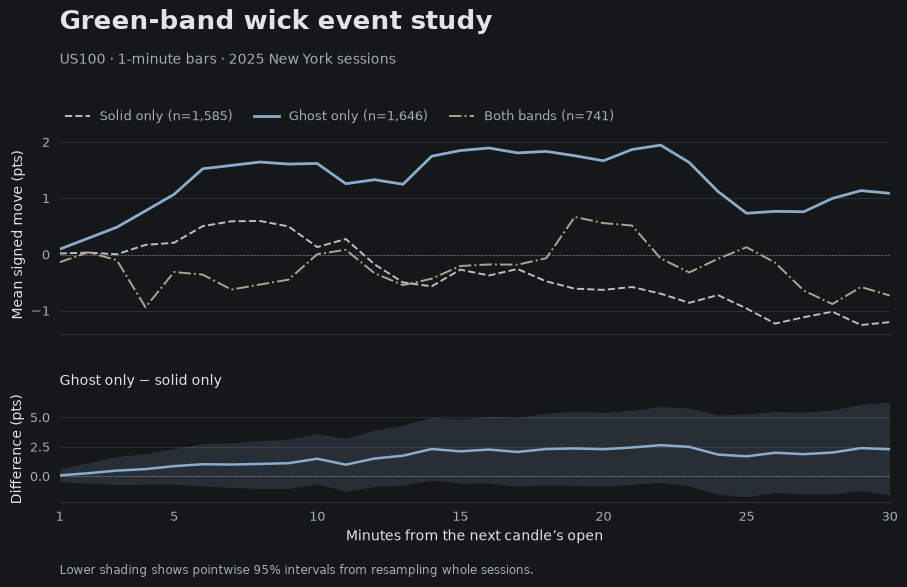

In [25]:
display(summary.round(2))

horizons = np.array(list(HORIZONS))
dates = pd.Index(trade_bars["session_date"].unique())
rng = np.random.default_rng(2025)
weights = rng.multinomial(
    len(dates), np.full(len(dates), 1 / len(dates)), size=2_000
)

styles = {
    "solid_only": ("Solid only", "#B5BEC9", "--", 1.4),
    "ghost_only": ("Ghost only", "#8CABCA", "-", 2.0),
    "both": ("Both bands", "#B0A293", "-.", 1.4),
}
means = {}
bootstrap = {}
counts = {}

for setup in styles:
    events = scored_events.loc[scored_events["setup"] == setup]
    counts[setup] = len(events)
    means[setup] = events[move_columns].mean().to_numpy()

    if setup == "both":
        continue

    by_day = events.groupby("session_date")
    daily_sums = by_day[move_columns].sum().reindex(dates, fill_value=0)
    daily_counts = by_day.size().reindex(dates, fill_value=0)
    sampled_sums = weights @ daily_sums.to_numpy()
    sampled_counts = (weights @ daily_counts.to_numpy())[:, None]
    bootstrap[setup] = np.divide(
        sampled_sums,
        sampled_counts,
        out=np.full_like(sampled_sums, np.nan, dtype=float),
        where=sampled_counts > 0,
    )

gap = means["ghost_only"] - means["solid_only"]
gap_draws = bootstrap["ghost_only"] - bootstrap["solid_only"]
lo, hi = np.nanpercentile(gap_draws, [2.5, 97.5], axis=0)

background = "#151719"
foreground = "#E1E4E8"
muted = "#A3ABB5"
grid = "#2F343B"
accent = styles["ghost_only"][1]

fig, (ax, gap_ax) = plt.subplots(
    2, 1, figsize=(10, 6.3), sharex=True, facecolor=background,
    gridspec_kw={"height_ratios": [1.9, 1]},
)
fig.subplots_adjust(left=0.13, right=0.96, top=0.76, bottom=0.18, hspace=0.42)

for axis in (ax, gap_ax):
    axis.set_facecolor(background)
    axis.spines[["top", "right", "left"]].set_visible(False)
    axis.spines["bottom"].set_color(grid)
    axis.set_axisbelow(True)
    axis.grid(axis="y", color=grid, linewidth=0.6)
    axis.axhline(0, color="#707983", linewidth=0.8, linestyle=":")
    axis.tick_params(colors=muted, labelsize=9, length=0, pad=7)

for setup, (label, color, linestyle, width) in styles.items():
    ax.plot(
        horizons, means[setup], color=color, linestyle=linestyle,
        linewidth=width, label=f"{label} (n={counts[setup]:,})",
    )

ax.set_ylabel("Mean signed move (pts)", color=foreground, fontsize=10)
ax.legend(
    loc="lower left", bbox_to_anchor=(0, 1.04), ncol=3,
    frameon=False, labelcolor=muted, fontsize=9,
    borderaxespad=0, columnspacing=1.7,
)

gap_ax.fill_between(horizons, lo, hi, color=accent, alpha=0.16, linewidth=0)
gap_ax.plot(horizons, gap, color=accent, linewidth=1.8)
gap_ax.set_title(
    "Ghost only − solid only", loc="left", color=foreground, fontsize=10, pad=9
)
gap_ax.set_ylabel("Difference (pts)", color=foreground, fontsize=10)
gap_ax.set_xlabel("Minutes from the next candle’s open", color=foreground, fontsize=10)
gap_ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
gap_ax.set_xlim(1, 30)

fig.text(
    0.13, 0.93, "Green-band wick event study",
    color=foreground, fontsize=19, weight="semibold",
)
fig.text(
    0.13, 0.875, "US100 · 1-minute bars · 2025 New York sessions",
    color=muted, fontsize=10,
)
fig.text(
    0.13, 0.065,
    "Lower shading shows pointwise 95% intervals from resampling whole sessions.",
    color=muted, fontsize=8.5,
)

save_report_figure(fig, "ghost_band_wick_event_study.png")
plt.show()

## 4. Baseline checks

### Match the green-band multipliers

Set the ghost green bands to ±1σ to match the solid bands. Recover the
ghost scale from the frozen band width and keep the original VWAP
snapshots, eligible candles, wick rule and 30-minute scoring window.

Compare the ghost-only minus solid-only mean move before and after
matching. Use the same resampled sessions for both versions to estimate
the uncertainty around the change.

In [20]:
from statistics import NormalDist

ghost_green_z = NormalDist().inv_cdf(CONFIG["ghost_upper_percentiles"][0])
ghost_scale = (
    comparable_bars["ghost_1+"] - comparable_bars["ghost_1-"]
) / (2 * ghost_green_z)

matched_bars = comparable_bars.assign(**{
    "ghost_1+": comparable_bars["vwap"] + ghost_scale,
    "ghost_1-": comparable_bars["vwap"] - ghost_scale,
})
matched_wicks = classify_wick_events(matched_bars)
matched_scored = score_wick_events(matched_wicks, forward_prices)

version_results = {}
for version, events, scored in (
    ("Original", wick_events, scored_events),
    ("Matched ±1σ", matched_wicks, matched_scored),
):
    groups = scored.groupby("setup")["move_30m"]
    version_results[version] = pd.DataFrame({
        "Setups": events.groupby("setup").size().reindex(setup_order, fill_value=0),
        "Scored": groups.size().reindex(setup_order, fill_value=0),
        "30m mean (pts)": groups.mean().reindex(setup_order),
    })

comparison = pd.concat(version_results, names=["Band version", "Setup"])
display(comparison.round(2))

matched_boot_means = {}
for setup in ("ghost_only", "solid_only"):
    by_day = matched_scored.loc[matched_scored["setup"].eq(setup)].groupby(
        "session_date"
    )["move_30m"]
    sampled_sums = weights @ by_day.sum().reindex(dates, fill_value=0).to_numpy()
    sampled_counts = weights @ by_day.size().reindex(dates, fill_value=0).to_numpy()
    matched_boot_means[setup] = np.divide(
        sampled_sums,
        sampled_counts,
        out=np.full(len(weights), np.nan),
        where=sampled_counts > 0,
    )

original_gap = gap[-1]
original_gap_draws = gap_draws[:, -1]

matched_means = version_results["Matched ±1σ"]["30m mean (pts)"]
matched_gap = matched_means["ghost_only"] - matched_means["solid_only"]
matched_gap_draws = matched_boot_means["ghost_only"] - matched_boot_means["solid_only"]

contrasts = []
for label, estimate, samples in (
    ("Original gap", original_gap, original_gap_draws),
    ("Matched gap", matched_gap, matched_gap_draws),
    ("Change in gap", matched_gap - original_gap, matched_gap_draws - original_gap_draws),
):
    valid_samples = samples[np.isfinite(samples)]
    lower, upper = (
        np.percentile(valid_samples, [2.5, 97.5])
        if len(valid_samples)
        else (np.nan, np.nan)
    )
    contrasts.append((label, estimate, lower, upper))

gap_comparison = pd.DataFrame(
    contrasts,
    columns=["Contrast", "Estimate (pts)", "95% CI low", "95% CI high"],
).set_index("Contrast")
display(gap_comparison.round(2))

Setups  Scored  30m mean (pts)
Band version Setup                                     
Original     solid_only    1939    1585           -1.20
             ghost_only    2024    1646            1.09
             both           856     741           -0.73
Matched ±1σ  solid_only    1863    1532           -1.71
             ghost_only    2023    1631           -0.59
             both           932     794            0.22

,Estimate (pts),95% CI low,95% CI high
Contrast,,,
Original gap,2.29,-1.56,6.29
Matched gap,1.12,-2.79,5.10
Change in gap,-1.17,-3.31,0.97
